<a href="https://colab.research.google.com/github/hema841/titanic-dataset-analysis/blob/main/various_data_cleaning_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load Titanic dataset
df = sns.load_dataset('titanic')

# Display first five rows
print("First Five Rows:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display dataset shape
print("\nDataset Shape:", df.shape)

First Five Rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------

In [2]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Total Missing Values: 869


In [3]:
cleaned_df = df.copy()
cleaned_df['age'] = cleaned_df['age'].fillna(
    cleaned_df['age'].median()
)
cleaned_df['embarked'] = cleaned_df['embarked'].fillna(
    cleaned_df['embarked'].mode()[0]
)
cleaned_df['deck'] = cleaned_df['deck'].cat.add_categories(
    ['Unknown']
).fillna('Unknown')
print("Missing Values After Cleaning:")
print(cleaned_df.isnull().sum())

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    2
alive          0
alone          0
dtype: int64


In [4]:
print("Duplicate Rows:", cleaned_df.duplicated().sum())
cleaned_df = cleaned_df.drop_duplicates()
print("Shape After Removing Duplicates:", cleaned_df.shape)

Duplicate Rows: 110
Shape After Removing Duplicates: (781, 15)


In [5]:
cleaned_df['sex'] = cleaned_df['sex'].str.strip().str.lower()
cleaned_df['who'] = cleaned_df['who'].str.strip().str.lower()
print("Unique Sex Values:")
print(cleaned_df['sex'].unique())
print("\nUnique Who Values:")
print(cleaned_df['who'].unique())

Unique Sex Values:
['male' 'female']

Unique Who Values:
['man' 'woman' 'child']


In [6]:
Q1 = cleaned_df['fare'].quantile(0.25)
Q3 = cleaned_df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = cleaned_df[
    (cleaned_df['fare'] < lower_bound) |
    (cleaned_df['fare'] > upper_bound)
]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Fare Outliers:", len(outliers))

Q1: 8.05
Q3: 34.0208
IQR: 25.9708
Lower Bound: -30.906200000000002
Upper Bound: 72.977
Number of Fare Outliers: 102


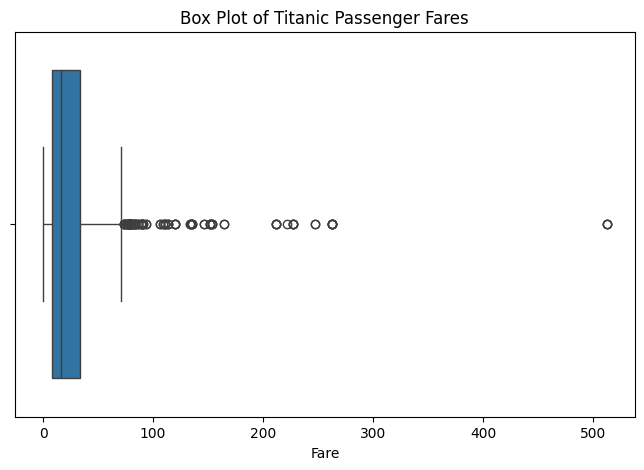

In [8]:
#visualize outliers using box plot
plt.figure(figsize=(8, 5))
sns.boxplot(x=cleaned_df['fare'])
plt.title("Box Plot of Titanic Passenger Fares")
plt.xlabel("Fare")
plt.show()

In [9]:
#validate numerical values
print(cleaned_df[['age', 'fare']].dtypes)
print("Negative Ages:",
      (cleaned_df['age'] < 0).sum())
print("Negative Fares:",
      (cleaned_df['fare'] < 0).sum())
print(cleaned_df[['age', 'fare']].describe())

age     float64
fare    float64
dtype: object
Negative Ages: 0
Negative Fares: 0
              age        fare
count  781.000000  781.000000
mean    29.622817   34.750464
std     13.764671   52.237906
min      0.420000    0.000000
25%     22.000000    8.050000
50%     28.000000   15.900000
75%     36.000000   34.020800
max     80.000000  512.329200


In [10]:
cleaned_df = cleaned_df.rename(columns={
    'survived': 'Survival_Status',
    'pclass': 'Passenger_Class',
    'age': 'Age',
    'fare': 'Fare'
})
print("Updated Column Names:")
print(cleaned_df.columns)

Updated Column Names:
Index(['Survival_Status', 'Passenger_Class', 'sex', 'Age', 'sibsp', 'parch',
       'Fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')


In [11]:
#display cleaned dataset
print("First Five Rows of Cleaned Dataset:")
print(cleaned_df.head())

print("\nFinal Dataset Shape:")
print(cleaned_df.shape)

print("\nRemaining Missing Values:")
print(cleaned_df.isnull().sum())

print("\nFinal Dataset Information:")
cleaned_df.info()

First Five Rows of Cleaned Dataset:
   Survival_Status  Passenger_Class     sex   Age  sibsp  parch     Fare  \
0                0                3    male  22.0      1      0   7.2500   
1                1                1  female  38.0      1      0  71.2833   
2                1                3  female  26.0      0      0   7.9250   
3                1                1  female  35.0      1      0  53.1000   
4                0                3    male  35.0      0      0   8.0500   

  embarked  class    who  adult_male     deck  embark_town alive  alone  
0        S  Third    man        True  Unknown  Southampton    no  False  
1        C  First  woman       False        C    Cherbourg   yes  False  
2        S  Third  woman       False  Unknown  Southampton   yes   True  
3        S  First  woman       False        C  Southampton   yes  False  
4        S  Third    man        True  Unknown  Southampton    no   True  

Final Dataset Shape:
(781, 15)

Remaining Missing Values:
Surv